# ESG ratings divergence: the research walkthrough

Four raters (MSCI, Sustainalytics, LSEG, S&P Global) score the same 30 companies. This notebook reproduces
every headline finding of the project in Python, using the `esg_divergence` package, which is tested to match
the TypeScript engine exactly.

> **Data status:** every rating is a *calibrated synthetic* value whose correlation structure matches
> Berg, Kölbel & Rigobon (2022). Suitable for demonstrating the methods; not a statement about any real company.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from esg_divergence import (universe_stats, correlation_matrix, permutation_null, bootstrap, universe,
                            screening_headline, analyse_all_screens, turnover_across_screens,
                            analyse_predictors, strongest, compute_divergence)
from esg_divergence.frame import ratings_frame, scores_wide, divergence_frame
from esg_divergence import figures

pd.set_option("display.precision", 1)

## 1 · Four scales, one axis
Sustainalytics is a *risk* score (lower is better) and is inverted; MSCI letters are intervals, so each carries an uncertainty band.

In [2]:
ratings_frame().query("ticker in ['XOM', 'TSLA', 'MSFT']")[['ticker','provider','raw','label','normalised','band_low','band_high','sector_percentile']]

,ticker,provider,raw,label,normalised,band_low,band_high,sector_percentile
0,XOM,msci,2.9,BB,29.0,28.6,42.9,25.0
1,XOM,sustainalytics,38.2,38.2 · High,23.6,20.0,40.0,8.3
2,XOM,lseg,66.0,66 · B,66.0,58.3,66.7,41.7
3,XOM,spcsa,61.0,61/100,61.0,58.5,63.5,91.7
28,MSFT,msci,9.3,AAA,93.0,85.7,100.0,75.0
29,MSFT,sustainalytics,13.9,13.9 · Low,72.2,60.0,80.0,91.7
30,MSFT,lseg,93.0,93 · A+,93.0,91.7,100.0,91.7
31,MSFT,spcsa,81.0,81/100,81.0,78.5,83.5,91.7
48,TSLA,msci,6.0,A,60.0,57.1,71.4,66.7
49,TSLA,sustainalytics,25.5,25.5 · Medium,49.0,40.0,60.0,25.0


In [3]:
scores_wide().describe().T[['mean','std','min','max']]

,mean,std,min,max
provider,,,,
msci,59.2,18.6,21.0,96.0
sustainalytics,49.5,13.3,23.6,72.2
lseg,73.6,10.7,56.0,94.0
spcsa,52.9,16.3,22.0,81.0


## 2 · How far apart are they?
`score = max(level spread, rank spread)`. Max, not average: agreement on rank must not cancel disagreement on level.

In [4]:
df = divergence_frame()
df[['name','sector','score','band','profile','level_range','rank_range']].head(10)

,name,sector,score,band,profile,level_range,rank_range
ticker,,,,,,,
SHEL,Shell plc,energy,80.0,extreme,both,57.8,80.0
XOM,Exxon Mobil Corporation,energy,63.3,extreme,both,42.4,63.3
BP,BP p.l.c.,energy,63.3,extreme,both,48.6,63.3
V,Visa Inc.,financials,61.7,extreme,both,24.6,61.7
NVDA,NVIDIA Corporation,technology,60.0,significant,rank,9.0,60.0
TSM,Taiwan Semiconductor Manufacturing,technology,56.7,significant,both,31.4,56.7
MCD,McDonald's Corporation,consumer,51.7,significant,rank,10.2,51.7
GE,GE Aerospace,industrials,50.0,significant,both,30.4,50.0
TSLA,"Tesla, Inc.",consumer,46.7,significant,both,28.0,46.7


In [5]:
universe_stats()

{'companies': 30,
 'providers': 4,
 'meanDivergence': 42.9,
 'maxDivergence': 80.0,
 'counts': {'aligned': 0, 'mild': 11, 'significant': 15, 'extreme': 4},
 'materialShare': 63.0,
 'mostDivergent': 'SHEL'}

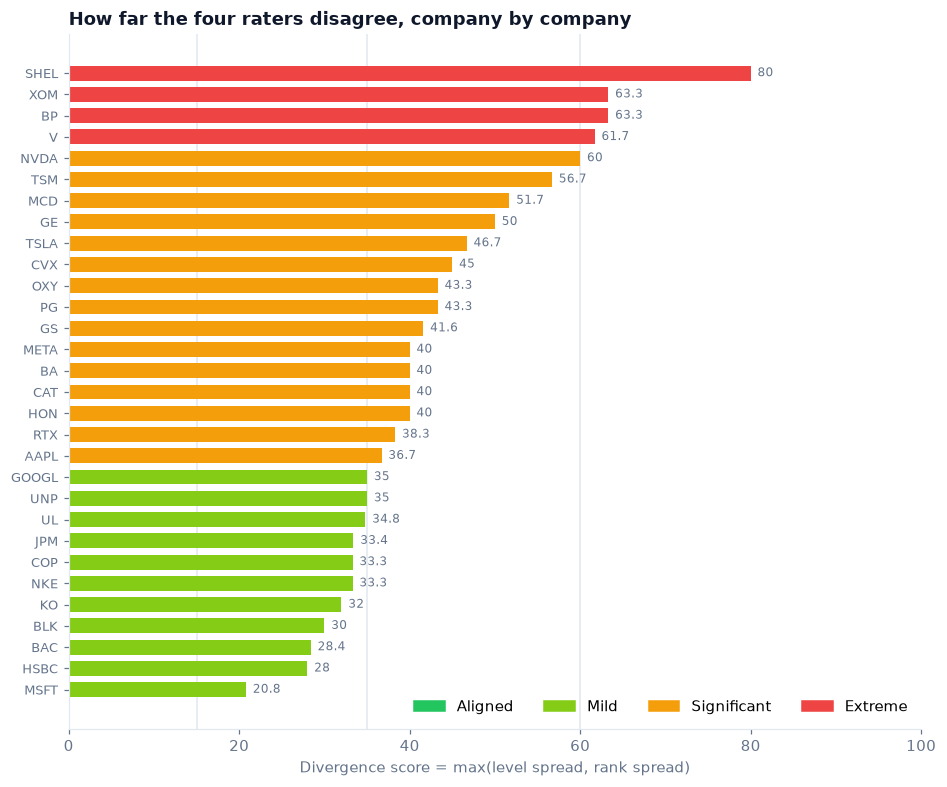

In [6]:
figures.fig_divergence_ranking();

In [7]:
pd.DataFrame([[correlation_matrix()[f'{a}:{b}'] for b in ['msci','sustainalytics','lseg','spcsa']] for a in ['msci','sustainalytics','lseg','spcsa']],
             index=['MSCI','Sustainalytics','LSEG','S&P'], columns=['MSCI','Sustainalytics','LSEG','S&P'])

,MSCI,Sustainalytics,LSEG,S&P
MSCI,1.0,0.5,0.6,0.6
Sustainalytics,0.5,1.0,0.4,0.6
LSEG,0.6,0.4,1.0,0.6
S&P,0.6,0.6,0.6,1.0


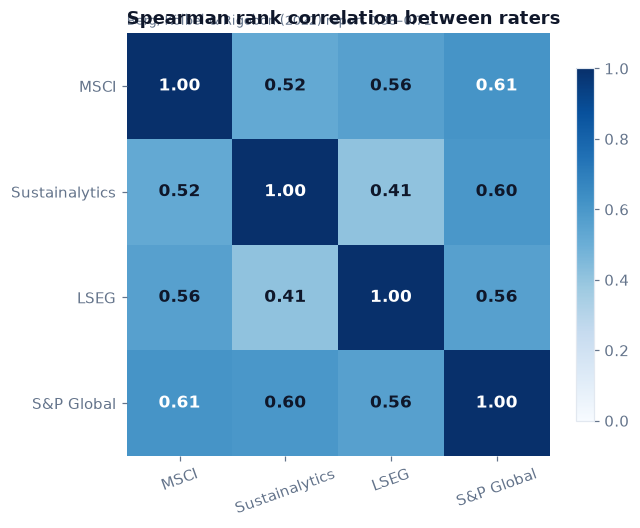

In [8]:
figures.fig_correlation_heatmap();

## 3 · Is the disagreement more than noise?
Shuffle each rater's scores independently: shared signal disappears, each rater's distribution is kept. If raters were unrelated, mean divergence would be ~60.

In [9]:
print('observed mean divergence:', bootstrap([r.divergence.score for r in universe()]))
null = permutation_null()
null

observed mean divergence: 42.9 (95% CI 38.4–47.7)


NullTest(observed=42.9, null_mean=60.7, null_low=55.3, null_high=65.7, p_value=0.0, iterations=500)

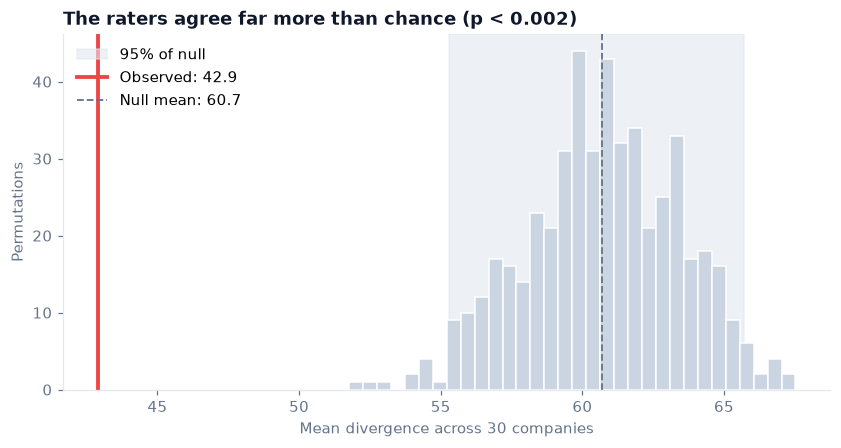

In [10]:
figures.fig_permutation_null();

## 4 · Is it predictable?
Four hypotheses, stated before looking at the data.

In [11]:
res = analyse_predictors()
pd.DataFrame([{'driver': r.id, 'compared': ' vs '.join(r.compared_groups), 'spread': r.spread,
               'cohens_d': r.effect_size, 'separated_CIs': r.separated, 'supported': r.supported} for r in res])

,driver,compared,spread,cohens_d,separated_CIs,supported
0,disclosure,Medium disclosure vs High disclosure,3.4,0.3,False,True
1,product,Product harms vs Product helps,3.4,0.2,False,True
2,controversy,None vs Moderate,11.8,1.1,False,False
3,carbon,High carbon vs Medium carbon,15.1,1.3,True,True


strongest driver: carbon


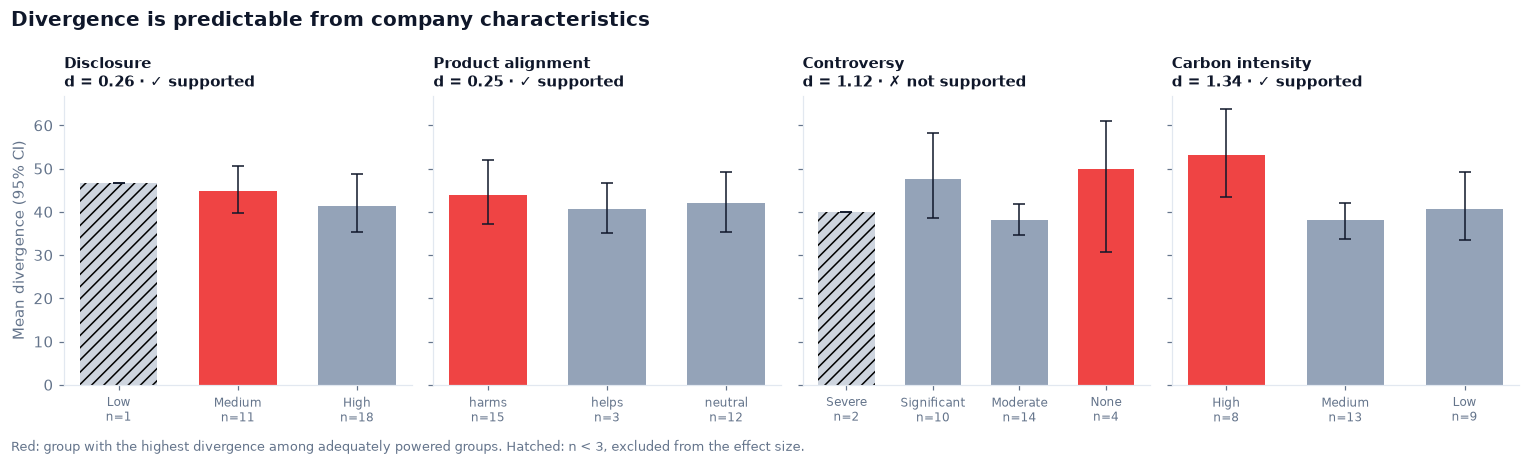

In [12]:
print('strongest driver:', strongest(res).id)
figures.fig_predictors();

In [13]:
df.groupby('carbon')['score'].agg(['mean','count']).sort_values('mean', ascending=False)

,mean,count
carbon,,
high,53.1,8
low,40.7,9
medium,38.0,13


## 5 · What does it cost a portfolio?

In [14]:
pd.DataFrame([s.summary() for s in analyse_all_screens()])[['id','contestedShare','minOverlap','portfolioSizeByProvider']]

,id,contestedShare,minOverlap,portfolioSizeByProvider
0,top_quartile,43.0,"{'a': 'msci', 'b': 'lseg', 'overlap': 38.0}","{'msci': 8, 'sustainalytics': 8, 'lseg': 7, 's..."
1,exclude_bottom_decile,27.0,"{'a': 'lseg', 'b': 'spcsa', 'overlap': 85.0}","{'msci': 27, 'sustainalytics': 27, 'lseg': 27,..."
2,absolute_threshold,63.0,"{'a': 'sustainalytics', 'b': 'lseg', 'overlap'...","{'msci': 22, 'sustainalytics': 15, 'lseg': 30,..."
3,best_in_class,57.0,"{'a': 'msci', 'b': 'sustainalytics', 'overlap'...","{'msci': 15, 'sustainalytics': 15, 'lseg': 15,..."


In [15]:
pd.DataFrame(turnover_across_screens())

,screen,a,b,nameTurnover,valueTurnover,costBpLow,costBpMid,costBpHigh
0,best_in_class,msci,sustainalytics,40.0,57.0,11.4,20.0,28.5
1,top_quartile,sustainalytics,lseg,63.0,46.0,9.1,15.9,22.8
2,absolute_threshold,sustainalytics,spcsa,27.0,17.0,3.4,5.9,8.5
3,exclude_bottom_decile,lseg,spcsa,15.0,8.0,1.6,2.8,4.0


In [16]:
screening_headline()

{'meanContestedShare': 48.0,
 'everContested': 28,
 'alwaysContested': [],
 'worstOverlap': {'screen': 'Top-quartile inclusion',
  'a': 'msci',
  'b': 'lseg',
  'overlap': 38.0},
 'worst': 'absolute_threshold',
 'best': 'exclude_bottom_decile'}

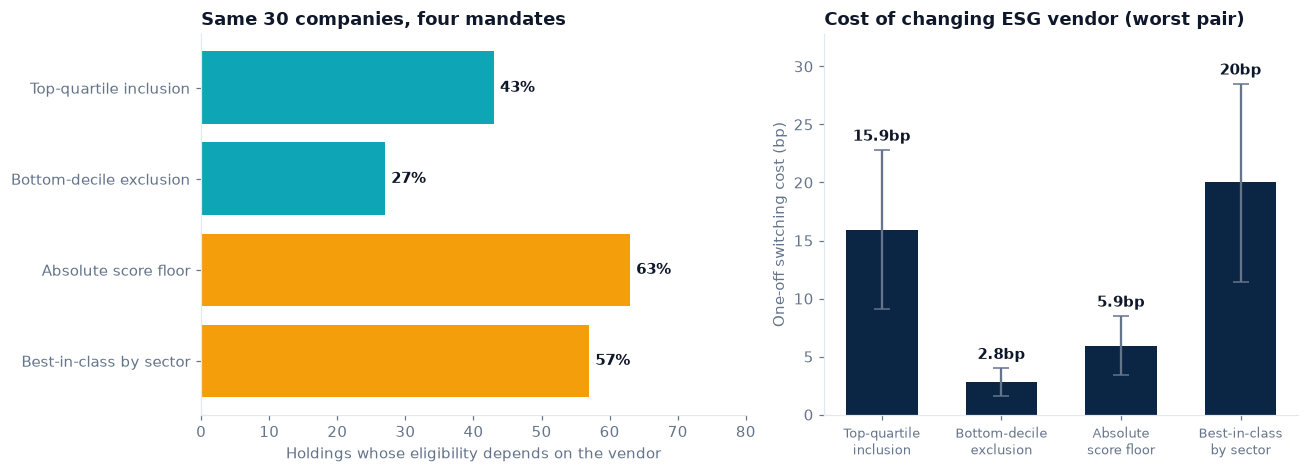

In [17]:
figures.fig_screening_impact();

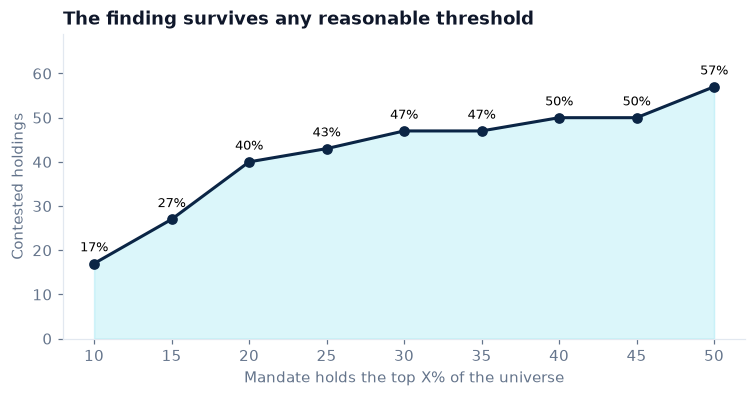

In [18]:
figures.fig_threshold_sensitivity();

## 6 · One company up close

In [19]:
d = compute_divergence('TSLA')
print(d.score, d.band, d.profile, d.pillar_ranges)
pd.DataFrame([p.__dict__ for p in d.pairs])

46.7 significant both {'environmental': 32.0, 'social': 51.0, 'governance': 60.6}


,a,b,normalised_delta,percentile_delta
0,msci,spcsa,28.0,40.0
1,lseg,spcsa,25.0,6.7
2,sustainalytics,spcsa,17.0,33.3
3,msci,sustainalytics,11.0,6.7
4,sustainalytics,lseg,8.0,40.0
5,msci,lseg,3.0,46.7


**Takeaways.** The raters measure a shared construct (p < 0.002), yet nearly half of holdings change eligibility with the vendor. Divergence is forecastable from carbon intensity (d ≈ 1.3), and rank-based screens are far more robust to vendor choice than absolute score floors.